# Análisis de resultados – Práctica 3 (Datos Masivos II)
PageRank, HITS y PageRank Sensible a Tópico sobre **cit-HepPh**, **Spotify** y **Wikipedia** (muestra y, si terminó, completa).

Antes de abrir este cuaderno hay que haber corrido, en este orden: `src/ingest/load_hepph.py`, `src/ingest/load_spotify.py`,
`src/ingest/parse_wiki.py` y `build_wiki_graph.py` (muestra), y `src/algos/run_all.py`. Este cuaderno solo **lee** los resultados
de `results/<dataset>/` y no usa Spark.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED, RESULTS = ROOT / "data" / "processed", ROOT / "results"
FIGS = ROOT / "report" / "figuras"; FIGS.mkdir(parents=True, exist_ok=True)
TABLES = RESULTS / "tablas"; TABLES.mkdir(parents=True, exist_ok=True)

# Datasets disponibles (los que ya tienen resultados) y la columna con el nombre legible del nodo
LABEL = {"hepph": "paper", "spotify": "name", "wiki_sample": "title", "wiki_full": "title"}
DATASETS = [d for d in LABEL if (RESULTS / d / "ranks.parquet").exists()]
print("Datasets con resultados:", DATASETS)
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)

Datasets con resultados: ['hepph', 'spotify', 'wiki_sample', 'wiki_full']


## 1. Carga y tamaños

In [2]:
def load(name):
    nodes = pd.read_parquet(PROCESSED / name / "nodes.parquet")
    edges = pd.read_parquet(PROCESSED / name / "edges.parquet")
    ranks = pd.read_parquet(RESULTS / name / "ranks.parquet")
    info = json.loads((RESULTS / name / "run_info.json").read_text())
    df = ranks.merge(nodes.drop(columns=[c for c in ("cats",) if c in nodes.columns]), on="id", how="left")
    df["label"] = df[LABEL[name]].astype(str)
    if name == "hepph" and (PROCESSED / "hepph" / "titles.parquet").exists():
        # SNAP solo trae ids: los títulos de los papers que salen en los rankings vienen de arXiv
        # (src/ingest/hepph_titles.py); se muestra "título (hep-ph/id, año)"
        t = pd.read_parquet(PROCESSED / "hepph" / "titles.parquet").set_index("paper").title
        aid = "hep-ph/" + df.paper.map(lambda p: f"{int(p):07d}")
        df["label"] = (df.paper.map(t).str.slice(0, 55) + " (" + aid + ", " + df.year.astype(str) + ")").fillna(aid)
    n = len(ranks)
    deg_in = np.bincount(edges.dst.to_numpy(), minlength=n)    # bincount: rápido y sin memoria extra
    deg_out = np.bincount(edges.src.to_numpy(), minlength=n)
    df["in_degree"] = deg_in[df.id.to_numpy()]
    df["out_degree"] = deg_out[df.id.to_numpy()]
    del edges   # no se guardan: en wiki_full son cientos de millones
    return df, None, info

data = {n: load(n) for n in DATASETS}
resumen = pd.DataFrame({
    n: {"nodos": info["nodos"], "aristas": info["aristas"], "sin_salida": info["nodos_sin_salida"],
        "iter PageRank": info["pagerank"]["iteraciones"], "iter HITS": info["hits"]["iteraciones"],
        "iter TSPR": info["tspr"]["iteraciones"], "segundos": info["segundos_total"]}
    for n, (_, _, info) in data.items()}).T
resumen.to_csv(TABLES / "resumen_datasets.csv")
resumen

,nodos,aristas,sin_salida,iter PageRank,iter HITS,iter TSPR,segundos
hepph,34546.0,421534.0,2393.0,49.0,100.0,55.0,244.7
spotify,156320.0,600758.0,2999.0,95.0,100.0,100.0,359.8
wiki_sample,153242.0,6780563.0,26.0,53.0,41.0,56.0,177.0
wiki_full,1516230.0,90351624.0,117.0,58.0,100.0,61.0,1420.1


## 2. Distribución de grados (log-log)

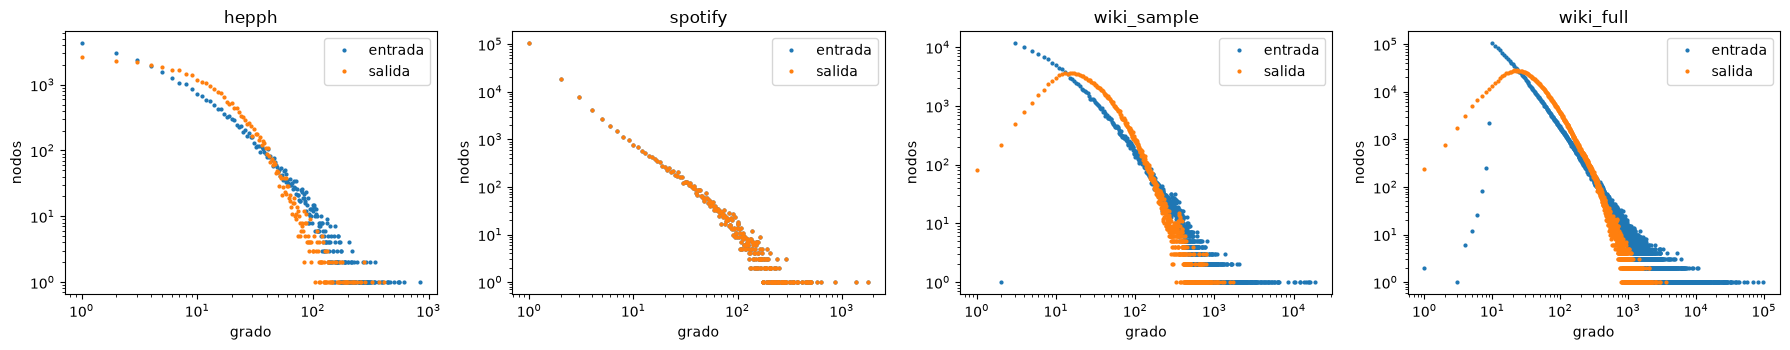

In [3]:
fig, axes = plt.subplots(1, len(data), figsize=(4.5 * len(data), 3.6), squeeze=False)
for ax, (n, (df, _, _)) in zip(axes[0], data.items()):
    for col, lab in (("in_degree", "entrada"), ("out_degree", "salida")):
        vc = df[col].value_counts().sort_index()
        vc = vc[vc.index > 0]
        ax.loglog(vc.index, vc.values, ".", ms=4, label=lab)
    ax.set_title(n); ax.set_xlabel("grado"); ax.set_ylabel("nodos"); ax.legend()
fig.tight_layout(); fig.savefig(FIGS / "distribucion_grados.pdf"); plt.show()

## 3. Top-20 por algoritmo y dataset

In [4]:
def top(df, col, k=20):
    t = df.sort_values(col, ascending=False).head(k)[["label", col, "in_degree", "out_degree"]]
    return t.reset_index(drop=True)

for n, (df, _, _) in data.items():
    for col in ("pagerank", "authority", "hub"):
        t = top(df, col)
        t.to_csv(TABLES / f"top20_{n}_{col}.csv", index=False)
        print(f"\n=== {n}: top-20 {col}")
        display(t)


=== hepph: top-20 pagerank


,label,pagerank,in_degree,out_degree
0,CTEQ Parton Distributions and Flavor Dependence of Sea ...,0.003521,154,0
1,"Total cross sections (hep-ph/9209205, 1992)",0.002720,343,0
2,ERRATUM TO: Power corrections $1/Q^2$ to parton sum rul ...,0.002398,106,0
3,Constraints From Gauge Coupling Unification On The Scal ...,0.002224,32,0
4,P-Wave Charmonium Production in B-Meson Decays (hep-ph/9...,0.002095,67,0
5,$SU(3)\otimes U(1)$ Model for Electroweak Interactions (...,0.001835,140,0
6,The Hierarchy Problem and New Dimensions at a Millimete ...,0.001820,846,0
7,Towards the Theory of Cosmological Phase Transitions (he...,0.001795,217,0
8,Dynamical Supersymmetry Breaking at Low Energies (hep-ph...,0.001624,347,1
9,Nambu Jona-Lasinio Like Models and the Low Energy Effec ...,0.001561,122,0



=== hepph: top-20 authority


,label,authority,in_degree,out_degree
0,The Hierarchy Problem and New Dimensions at a Millimete ...,0.409000,846,0
1,New Dimensions at a Millimeter to a Fermi and Superstri ...,0.333022,616,6
2,"Phenomenology, Astrophysics and Cosmology of Theories w ...",0.287051,503,7
3,Quantum Gravity and Extra Dimensions at High-Energy Col ...,0.195909,286,24
4,A Large Mass Hierarchy from a Small Extra Dimension (hep...,0.188321,449,16
5,On Kaluza-Klein States from Large Extra Dimensions (hep-...,0.180304,255,16
6,Extra Spacetime Dimensions and Unification (hep-ph/98034...,0.172975,305,3
7,Collider Signatures of New Large Space Dimensions (hep-p...,0.168654,219,9
8,Grand Unification at Intermediate Mass Scales through E ...,0.159061,289,14
9,Indirect Collider Signals for Extra Dimensions (hep-ph/9...,0.156665,207,10



=== hepph: top-20 hub


,label,hub,in_degree,out_degree
0,Testing the Nature of Kaluza-Klein Excitations at Futur ...,0.094772,38,109
1,The Beyond the Standard Model Working Group: Summary Re ...,0.093279,3,229
2,"Theories in More than Four Dimensions (hep-ph/0008333, 2...",0.092772,16,94
3,Theory and Phenomenology of Type I strings and M-theory ...,0.079745,5,80
4,Gauge Coupling Unification with Extra Dimensions and Co ...,0.078309,25,66
5,Seeking TeV-Scale Quantum Gravity at an $e γ$ collider (...,0.077271,9,78
6,Particle Physics Probes Of Extra Spacetime Dimensions (h...,0.074451,12,77
7,Indirect Collider Tests for Large Extra Dimensions (hep-...,0.074210,22,78
8,Recent Developments in Physics Beyond the Standard Mode ...,0.072951,6,70
9,Cumulative Non-Decoupling Effects of Kaluza-Klein Neutr ...,0.072176,44,73


... (14 outputs left out)


=== wiki_full: top-20 authority


,label,authority,in_degree,out_degree
0,2020 United States census,0.197933,20146,128
1,U.S. state,0.197033,24744,256
2,Race and ethnicity in the United States census,0.187227,18523,117
3,United States Census Bureau,0.179255,18052,99
4,African Americans,0.176318,21720,750
5,World War II,0.166270,82907,833
6,Native Americans in the United States,0.164316,18210,614
7,Federal Information Processing Standards,0.159812,15957,28
8,Hispanic and Latino Americans,0.158400,15010,1398
9,Poverty threshold,0.153822,15040,64



=== wiki_full: top-20 hub


,label,hub,in_degree,out_degree
0,United States,0.014648,69803,1340
1,Hispanic and Latino Americans,0.014343,15010,1398
2,2025 in the United States,0.014205,58,1798
3,Demonym,0.014172,786,1025
4,21st century,0.013105,58,2026
5,New York (state),0.013054,21148,977
6,2020s,0.012479,13,2199
7,Tennessee,0.012338,6044,924
8,New Jersey,0.012183,11057,1049
9,"Jersey City, New Jersey",0.012164,2110,933


## 4. PageRank vs HITS vs grado de entrada

In [5]:
filas = []
for n, (df, _, _) in data.items():
    s = df[["pagerank", "authority", "hub", "in_degree", "out_degree"]].rank()
    corr = s.corr()
    filas.append({"dataset": n,
                  "PR~in_degree": corr.loc["pagerank", "in_degree"],
                  "PR~authority": corr.loc["pagerank", "authority"],
                  "PR~hub": corr.loc["pagerank", "hub"],
                  "authority~hub": corr.loc["authority", "hub"],
                  "top20 PR∩authority": len(set(top(df, "pagerank").label) & set(top(df, "authority").label)) / 20,
                  "top20 PR∩in_degree": len(set(top(df, "pagerank").label) & set(top(df, "in_degree").label)) / 20})
cmp_df = pd.DataFrame(filas).set_index("dataset").round(3)
cmp_df.to_csv(TABLES / "comparacion_algoritmos.csv")
cmp_df   # Spearman entre rangos y solapamiento del top-20

,PR~in_degree,PR~authority,PR~hub,authority~hub,top20 PR∩authority,top20 PR∩in_degree
dataset,,,,,,
hepph,0.910,0.665,-0.008,0.481,0.05,0.15
spotify,0.785,-0.035,-0.035,1.000,0.10,0.85
wiki_sample,0.899,0.431,-0.012,0.687,0.45,0.75
wiki_full,0.735,0.573,0.135,0.568,0.15,0.75


**Nota para Spotify:** la red es no dirigida (cada colaboración son dos aristas), así que `authority` y `hub` coinciden
y PageRank es casi proporcional al grado. Es un efecto del grafo simétrico, no un error del algoritmo.

### Concentración de HITS
HITS converge al vector propio principal de $L^\top L$, que tiende a concentrarse en la comunidad más densa
del grafo. Por eso muchos nodos tienen autoridad prácticamente cero y la correlación de Spearman con PageRank
puede ser baja aunque los dos rankings tengan sentido.

In [6]:
filas = []
for n, (df, _, _) in data.items():
    a = np.sort(df.authority.to_numpy() ** 2)[::-1]       # masa L2 (suma 1)
    k = max(1, len(a) // 100)
    filas.append({"dataset": n, "nodos": len(a),
                  "autoridad > 1e-6 (fracción)": (np.sqrt(a) > 1e-6).mean(),
                  "masa L2 en el top 1 %": a[:k].sum(),
                  "masa PageRank en el top 1 %": np.sort(df.pagerank.to_numpy())[::-1][:k].sum()})
conc = pd.DataFrame(filas).set_index("dataset").round(3)
conc.to_csv(TABLES / "concentracion.csv")
conc

,nodos,autoridad > 1e-6 (fracción),masa L2 en el top 1 %,masa PageRank en el top 1 %
dataset,,,,
hepph,34546,0.743,0.917,0.196
spotify,156320,0.667,0.966,0.226
wiki_sample,153242,0.951,0.996,0.202
wiki_full,1516230,0.996,0.983,0.279


## 5. Convergencia

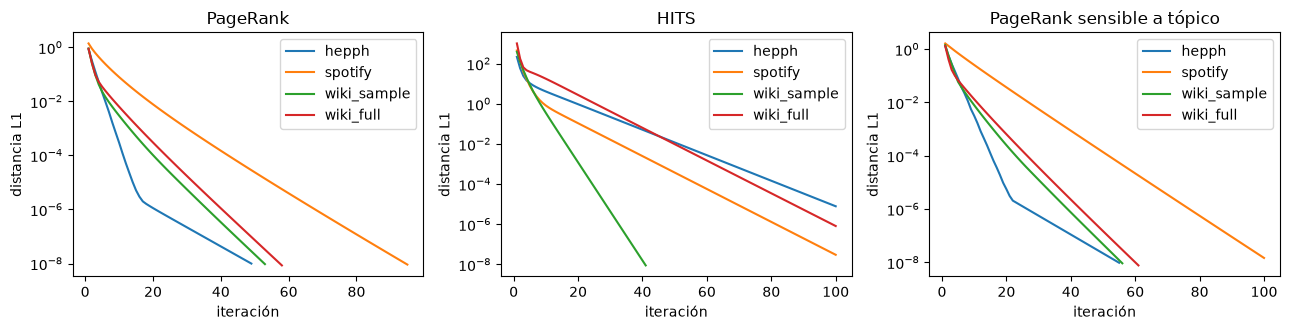

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (key, titulo) in zip(axes, (("pagerank", "PageRank"), ("hits", "HITS"), ("tspr", "PageRank sensible a tópico"))):
    for n, (_, _, info) in data.items():
        ax.semilogy(range(1, len(info[key]["historia"]) + 1), info[key]["historia"], label=n)
    ax.set_title(titulo); ax.set_xlabel("iteración"); ax.set_ylabel("distancia L1"); ax.legend()
fig.tight_layout(); fig.savefig(FIGS / "convergencia.pdf"); plt.show()

## 6. PageRank sensible a tópico: top-10 por tópico

In [8]:
def topic_cols(df): return [c for c in df.columns if c.startswith("tspr_")]

for n, (df, _, _) in data.items():
    cols = topic_cols(df)
    tabla = pd.DataFrame({c.removeprefix("tspr_"): df.sort_values(c, ascending=False).head(10).label.values for c in cols})
    tabla.index = range(1, 11)
    tabla.to_csv(TABLES / f"tspr_top10_{n}.csv")
    print(f"\n=== {n}: top-10 por tópico")
    display(tabla)


=== hepph: top-10 por tópico


,1992_1994,1995_1997,1998_2000,2001_2003
1,Towards the Theory of Cosmological Phase Transitions (he...,CTEQ Parton Distributions and Flavor Dependence of Sea ...,CTEQ Parton Distributions and Flavor Dependence of Sea ...,The Hierarchy Problem and New Dimensions at a Millimete ...
2,Constraints From Gauge Coupling Unification On The Scal ...,ERRATUM TO: Power corrections $1/Q^2$ to parton sum rul ...,"Total cross sections (hep-ph/9209205, 1992)",CTEQ Parton Distributions and Flavor Dependence of Sea ...
3,CTEQ Parton Distributions and Flavor Dependence of Sea ...,P-Wave Charmonium Production in B-Meson Decays (hep-ph/9...,The Hierarchy Problem and New Dimensions at a Millimete ...,"Total cross sections (hep-ph/9209205, 1992)"
4,ERRATUM TO: Power corrections $1/Q^2$ to parton sum rul ...,"Total cross sections (hep-ph/9209205, 1992)",ERRATUM TO: Power corrections $1/Q^2$ to parton sum rul ...,Dynamical supersymmetry breaking with a large internal ...
5,$SU(3)\otimes U(1)$ Model for Electroweak Interactions (...,Constraints From Gauge Coupling Unification On The Scal ...,$SU(3)\otimes U(1)$ Model for Electroweak Interactions (...,New Dimensions at a Millimeter to a Fermi and Superstri ...
6,P-Wave Charmonium Production in B-Meson Decays (hep-ph/9...,Measurement of the Spin-Dependent Structure Function $g ...,Constraints From Gauge Coupling Unification On The Scal ...,$SU(3)\otimes U(1)$ Model for Electroweak Interactions (...
7,Radiative Correction Effects of a Very Heavy Top (hep-ph...,Consistent Analysis of the Spin Content of the Nucleon (...,P-Wave Charmonium Production in B-Meson Decays (hep-ph/9...,Constraints From Gauge Coupling Unification On The Scal ...
8,Test of the Dimopouos-Hall-Raby Ansatz for Fermion Mass ...,Dynamical Supersymmetry Breaking at Low Energies (hep-ph...,Dynamical Supersymmetry Breaking at Low Energies (hep-ph...,Nambu Jona-Lasinio Like Models and the Low Energy Effec ...
9,Two-loop renormalization of the effective field theory ...,Towards the Theory of Cosmological Phase Transitions (he...,Dynamical supersymmetry breaking with a large internal ...,ERRATUM TO: Power corrections $1/Q^2$ to parton sum rul ...
10,Troubles with the Minimal SU(5) Supergravity Model (hep-...,"Parton Distributions of the Proton (hep-ph/9406315, 1994)",Implication of Combined Solar Neutrino Observation and ...,Extra Spacetime Dimensions and Unification (hep-ph/98034...



=== spotify: top-10 por tópico


,clasica,country_folk,electronica,hip_hop,jazz_blues_soul,latino,metal,pop,rock
1,Johann Sebastian Bach,Traditional,Armin van Buuren,Gucci Mane,Mc Gw,Elis Regina,S3RL,Raimonds Pauls,Johann Sebastian Bach
2,Jean Sibelius,Dolly Parton,Moby,Mozzy,MC MN,Redimi2,Tarja,Traditional,demxntia
3,Traditional,Nashville Cast,Tiësto,Fumez The Engineer,Louis Armstrong,Alex Zurdo,Electric Callboy,Renuka Panwar,Txarango
4,John Williams,Johnny Cash,Tritonal,Snoop Dogg,Mc Rd,Ñengo Flow,Armin van Buuren,Tiësto,Diplo
5,Iceland Symphony Orchestra,MC Stojan,Diplo,Tech N9ne,Mc Delux,Luis R Conriquez,Kool G Rap,Steve Aoki,Steve Aoki
6,Andrea Bocelli,Jelly Roll,Steve Aoki,Waka Flocka Flame,Dj Batata,Moncho Chavea,HEALTH,R3HAB,RAC
7,Ennio Morricone,The Dubliners,Roger Shah,Eko Fresh,Snoop Dogg,Luis Alfonso Partida El Yaki,DJ Gollum,A.R. Rahman,Tiësto
8,Rolf Zuckowski,Rasta,Above & Beyond,The Game,John Williams,Miel San Marcos,Steve Aoki,Diplo,Moby
9,Adolphe Adam,Mercedes Sosa,Depeche Mode,SFDK,Mc Cyclope,Rodrigo Tapari,Pappo,Pritam,Jimmy Barnes
10,Fazıl Say,Dierks Bentley,David Guetta,Max B,Incognito,Farruko,Apocalyptica,Armin van Buuren,Bi-2



=== wiki_sample: top-10 por tópico


,arte_cultura,ciencia,deportes,geografia,historia,negocios,politica,religion,salud,tecnologia
1,World War II,Latin,World War II,United States Census Bureau,World War II,World War II,World War II,World War II,World War II,World War II
2,The New York Times,Mathematics,Association football,Geographic Names Information System,United Kingdom,United Kingdom,United Kingdom,Latin,Latin,Microsoft Windows
3,London,World War II,Major League Baseball,Per capita income,Latin,London,Soviet Union,Christianity,United Kingdom,Operating system
4,Latin,Genus,Baseball,Marriage,London,Latin,Latin,United Kingdom,The New York Times,United Kingdom
5,United Kingdom,Carl Linnaeus,United Kingdom,Census,Soviet Union,The New York Times,Republican Party (United States),Rome,London,Microsoft
6,Los Angeles,Ancient Greek,National Football League,Native Americans in the United States,Germany,Germany,"Washington, D.C.",Roman Empire,Soviet Union,C (programming language)
7,Soviet Union,Physics,London,Population density,Roman Empire,Soviet Union,London,Middle Ages,"Washington, D.C.",Soviet Union
8,Paris,United Kingdom,Latin,Asian Americans,China,China,European Union,London,Germany,Mathematics
9,"Washington, D.C.",Family (taxonomy),The New York Times,African Americans,Middle Ages,"Washington, D.C.",United States Congress,Germany,China,Computer science
10,Germany,Europe,National Hockey League,World War II,Ottoman Empire,European Union,Germany,Soviet Union,Ancient Greek,Programming language



=== wiki_full: top-10 por tópico


,arte_cultura,ciencia,deportes,geografia,historia,negocios,politica,religion,salud,tecnologia
1,World War II,United States,Association football,World War II,World War II,United States,World War II,Catholic Church,World War II,World War II
2,United States,World War II,United States,United States,United States,World War II,United States,World War II,United States,United States
3,New York City,Genus,World War II,U.S. state,World War I,United Kingdom,Democratic Party (United States),United States,United Kingdom,United Kingdom
4,The New York Times,Latin,Basketball,2020 United States census,United Kingdom,New York City,Republican Party (United States),Latin,New York City,Microsoft Windows
5,London,Mathematics,American football,United States Census Bureau,London,London,United Kingdom,World War I,World War I,New York City
6,Los Angeles,Species,Midfielder,France,Catholic Church,World War I,India,India,London,World War I
7,Drama (film and television),United Kingdom,National Football League,Race and ethnicity in the United States census,France,Chief executive officer,World War I,United Kingdom,The New York Times,Single-player video game
8,United Kingdom,Carl Linnaeus,COVID-19 pandemic,Catholic Church,Latin,France,United States House of Representatives,France,Catholic Church,The New York Times
9,World War I,China,France,Köppen climate classification,Soviet Union,Germany,Independent politician,Christianity,Latin,Metacritic
10,India,France,Ice hockey,World War I,Germany,China,Catholic Church,New York City,France,London


### Qué distingue a cada tópico (lift sobre PageRank)
En el ranking crudo de cada tópico siguen arriba las páginas importantes en general (con $\beta=0.85$ el 85 % de
la masa sigue los enlaces). Para ver lo propio de cada tópico se ordena por el cociente $r_t(v)/r(v)$ (cuánto
gana el nodo al sesgar el teletransporte), solo entre los 1 000 primeros de $r_t$ para no premiar nodos marginales.

In [9]:
TOP_POOL = 1000
for n, (df, _, _) in data.items():
    tabla = {}
    for c in topic_cols(df):
        pool = df.nlargest(TOP_POOL, c)
        tabla[c.removeprefix("tspr_")] = pool.assign(lift=pool[c] / pool.pagerank).nlargest(10, "lift").label.values
    tabla = pd.DataFrame(tabla, index=range(1, 11))
    tabla.to_csv(TABLES / f"tspr_lift_top10_{n}.csv")
    print(f"\n=== {n}: top-10 por lift r_t / PageRank")
    display(tabla)


=== hepph: top-10 por lift r_t / PageRank


,1992_1994,1995_1997,1998_2000,2001_2003
1,"The Process of Generation of Mass, The Higgs Boson, and ...","Neutrino masses and mixing (hep-ph/9601266, 1996)",Dilatonic Dark Matter and Unified Cosmology -- a New Pa ...,Hadronic scattering amplitudes: medium-energy constrain ...
2,Phenomenology of Multi-W Processes in Cosmic Rays (hep-p...,A demonstration that the observed neutrinos are not Maj ...,"Dilatonic Dark Matter (hep-ph/9810379, 1998)",Hadron production in Au-Au collisions at RHIC (hep-ph/01...
3,Equilibrium Relativistic Mass Distribution (hep-ph/93122...,Dual Higgs Mechanism for Quarks in Hadrons (hep-ph/95022...,Non-leptonic hyperon decays in chiral perturbation theo ...,High-precision calculation of multi-loop Feynman integr ...
4,Monopoles and Quark Confinement: Introduction and Overv ...,Charmed Baryon Masses in Chiral Perturbation Theory (hep...,Quark Propagation in a Quark-Gluon Plasma with Gluon Co ...,Structure Functions are not Parton Probabilities (hep-ph...
5,Finite-element quantum electrodynamics. II. Lattice pro ...,LHC Analysis of the Strongly Interacting $WW$ System: G ...,Constraints on the parameters of the $V_{CKM}$ matrix a ...,MRST2001: partons and alpha_S from precise deep inelast ...
6,"Quark confinement , topological susceptibility and all ...",One Loop Graviton Self-Energy In A Locally De Sitter Ba ...,On the odderon intercept in the variational approach (he...,Semiclassical suppression of black hole production in p ...
7,"The $η_6$ at LEP and TRISTAN (hep-ph/9301251, 1993)",Chiral Perturbation Theory for Vector Mesons (hep-ph/950...,"On the physics of massive neutrinos (hep-ph/9811267, 1998)",The Cosmological Evolution of the Nucleon Mass and the ...
8,Dynamical CP Violation in Composite Higgs Models (hep-ph...,"$ξ(2230)$ is likely to be a glueball (hep-ph/9502408, 1995)",Standard Model Confronting New Results for epsilon'/eps ...,The Weak Mixing Angle from an SU(3) Symmetry at a TeV (h...
9,On the Origin of the Enhancementof CP-violating Charge ...,Confining Bethe--Salpeter equation from scalar QCD (hep-...,"Estimating epsilon'/epsilon. A Review (hep-ph/9802405, 1...","Black Holes at the LHC (hep-ph/0106295, 2001)"
10,"New QCD Effects at Large x (hep-ph/9210267, 1992)",SUPPRESSION OF THE NEUTRON-ANTINEUTRON OSCILLATION IN N ...,Low-Energy Parity-Violation and New Physics (hep-ph/9903...,High Energy Colliders as Black Hole Factories: The End ...



=== spotify: top-10 por lift r_t / PageRank


,clasica,country_folk,electronica,hip_hop,jazz_blues_soul,latino,metal,pop,rock
1,Veljo Tormis,Hideaki Tokunaga,Sphera,Roham,The Black Keys,Los Charros De Lumaco,System Of A Down,Datuk Ahmad Jais,AaRON
2,Tõnu Kaljuste,Zach Bryan,Axel Wikner,Lil God Dan,tonun,David Santos,Viikate,siouxxie sixxsta,Ritt Momney
3,Tõnu Kõrvits,Maaike Ouboter,Captain Hollywood Project,LEXIKA,Tokimeki Records,Eddie Santiago,Dave Martone,"Arturo ""Zambo"" Cavero",Purahei Soul
4,Tallin Chamber Orchestra,Pang Nakarin,DJ Blyatman,Dv,Billy F Gibbons,Los Farmerz,Bruce Kulick,Anne Mattila,Andy Bull
5,Marielle Labèque,The Saw Doctors,Helios,Huzz,Ben E. King,Efecto Elegante,Dee Snider,Don Medardo y Sus Players,Midnight Fusic
6,Misha Dichter,Michael Prins,Eliza Rose,1nonly,Jessé Aguiar,JR Torres,Of Mice & Men,Chamath Sangeeth,Disturbed
7,Luciana Serra,Petula Clark,Lowercase Noises,makko,Sam Cooke,Don Medardo y Sus Players,From Ashes to New,Duy Khanh,Eve 6
8,Kurt Moll,Koji Tamaki,Bicep,BODIEV,The Drifters,Los Vikings 5,Wu-Tang Clan,DA PUMP,Dato' Sudirman
9,Werner Haas,Charles Wesley Godwin,Moderat,MrsProd,Kurt Elling,Adalberto Santiago,David Draiman,Jens Book-Jenssen,La Máquina Camaleón
10,Ann Murray,Takkatan Chollada,Berg,Shotgun Willy,Gabriela Rocha,Victor Cibrian,CMX,Marijonas Mikutavičius,José Madero



=== wiki_sample: top-10 por lift r_t / PageRank


,arte_cultura,ciencia,deportes,geografia,historia,negocios,politica,religion,salud,tecnologia
1,Q (magazine),Charles Lucien Bonaparte,The Ring (magazine),Township (United States),Peerage of the United Kingdom,Jandek,Local government areas of Victoria,Free Democratic Party of Switzerland,Urology,Single-player video game
2,Robert Christgau,John Edward Gray,World Boxing Association,Civil township,2001 United Kingdom general election,Federal Department of Finance,Politics of Quebec,Gaius Julius Hyginus,Antipsychotic,Multiplayer video game
3,Entertainment Weekly,Passerine,International Boxing Federation,"Potter County, Pennsylvania",1997 United Kingdom general election,Livery company,Timeline of Quebec history,Federal Council (Switzerland),Nonsteroidal anti-inflammatory drug,Fork (software development)
4,NME,Pierre André Latreille,World Boxing Council,Census,The Right Honourable,Order of precedence,Quebec Liberal Party,Pausanias (geographer),Pancreatic cancer,Arcade video game
5,Extended play,Insectivore,Knockout,Per capita income,Privy Council (United Kingdom),Video game industry,Free Democratic Party of Switzerland,Hera,Immunosuppression,OpenGL
6,Comedy film,Type species,World Boxing Organization,Federal Information Processing Standards,Order of the British Empire,Holding company,Federal Council (Switzerland),Holy orders,Emergency medicine,Floating-point unit
7,Elektra Records,Bird migration,Middleweight,Geographic Names Information System,Order of the Bath,Derivative (finance),Progressive Conservative Party of Canada,Poseidon,Hypothyroidism,HP-UX
8,Epic Records,Subspecies,International Boxing Hall of Fame,Marriage,Colonel,Nasdaq,National Assembly of Quebec,John Chrysostom,American Academy of Pediatrics,GNU Lesser General Public License
9,Roger Ebert,Binomial nomenclature,Fielding (cricket),Population density,Liberal Party (UK),Takeover,Labour Party (Ireland),Council of Chalcedon,Hypotension,Symmetric multiprocessing
10,Rolling Stone,Beak,Over (cricket),Census-designated place,Speaker of the House of Commons (United Kingdom),Private equity,By-election,Christology,Dermatology,Method (computer programming)



=== wiki_full: top-10 por lift r_t / PageRank


,arte_cultura,ciencia,deportes,geografia,historia,negocios,politica,religion,salud,tecnologia
1,K. J. Yesudas,Fauna Hawaiiensis,Tercera División,Classification of municipalities in Quebec,Division (military),Professional Darts Corporation,None of the above (India),Eminence (style),Psychological thriller,Single-player video game
2,S. Janaki,Cosmopterigidae,ESPN3,Historical federal electoral districts of Canada,Regiment,Darts,Janata Party,Titular bishop,Oral administration,Famitsu
3,K. S. Chithra,"Thomas de Grey, 6th Baron Walsingham",Midfielder,Regional county municipality,United Kingdom constituencies,Kabushiki gaisha,None of the above,Bibliotheca (Apollodorus),Trauma center,GamePro
4,S. P. Balasubrahmanyam,Paleoart,Defender (association football),Canadian provincial electoral districts,Brigade,Privately held company,Communist Party of India,Suffragan bishop,Residency (medicine),Electronic Gaming Monthly
5,Intertitle,Holotype,AP poll,Community development block,Order of the Bath,Video game developer,Pennsylvania House of Representatives,Roman Rite,WHO Model List of Essential Medicines,Next Generation (magazine)
6,Comedy film,Specific name (zoology),European Athletics Championships,Riding (division),Member of Parliament (United Kingdom),Video game industry,Communist Party of India (Marxist),Ecclesiastical province,Generic drug,Multiplayer video game
7,Pre-Code Hollywood,Type species,Forward (association football),Measuring poverty,Infantry,Subsidiary,Massachusetts House of Representatives,Pope Paul VI,Teaching hospital,GameSpot
8,Romance film,Theropoda,200 metres,Electoral district (Canada),Battalion,Public company,Member of the Legislative Assembly (India),Holy orders,Internal medicine,Game Informer
9,Mystery film,Edward Drinker Cope,Primeira Liga,Postal codes in Canada,Lieutenant general,Private equity,Indian National Congress,Bishops in the Catholic Church,Oncology,Action role-playing game
10,Rediff.com,Maastrichtian,Copa del Rey,Municipalities of the Philippines,Act of Parliament (United Kingdom),S.A. (corporation),Bharatiya Janata Party,Pope John XXIII,European Medicines Agency,Platformer


### Combinación en el momento de la consulta
`r = Σ_t w_t · r_t`: los pesos `w_t` expresan el interés del usuario (p. ej. 70 % ciencia + 30 % tecnología).
Cambia `PESOS` por tópicos que existan en cada dataset (ver columnas `tspr_*`).

In [10]:
PESOS = {
    "hepph": {"1992_1994": 0.7, "1995_1997": 0.3},
    "spotify": {"rock": 0.6, "electronica": 0.4},
    "wiki_sample": {"ciencia": 0.7, "tecnologia": 0.3},
    "wiki_full": {"ciencia": 0.7, "tecnologia": 0.3},
}
for n, (df, _, _) in data.items():
    w = {("tspr_" + t): v for t, v in PESOS.get(n, {}).items() if ("tspr_" + t) in df.columns}
    if not w:
        print(n, ": ningún tópico de PESOS existe en este dataset"); continue
    total = sum(w.values())
    q = sum(df[c] * v / total for c, v in w.items())
    resultado = df.assign(consulta=q).sort_values("consulta", ascending=False).head(10)[["label", "consulta", "pagerank"]]
    print(f"\n=== {n}: consulta {PESOS[n]}")
    display(resultado.reset_index(drop=True))


=== hepph: consulta {'1992_1994': 0.7, '1995_1997': 0.3}


,label,consulta,pagerank
0,Towards the Theory of Cosmological Phase Transitions (he...,0.004899,0.001795
1,CTEQ Parton Distributions and Flavor Dependence of Sea ...,0.004821,0.003521
2,Constraints From Gauge Coupling Unification On The Scal ...,0.004695,0.002224
3,ERRATUM TO: Power corrections $1/Q^2$ to parton sum rul ...,0.003680,0.002398
4,P-Wave Charmonium Production in B-Meson Decays (hep-ph/9...,0.003453,0.002095
5,$SU(3)\otimes U(1)$ Model for Electroweak Interactions (...,0.003029,0.001835
6,"Total cross sections (hep-ph/9209205, 1992)",0.002846,0.002720
7,Radiative Correction Effects of a Very Heavy Top (hep-ph...,0.002824,0.001275
8,Two-loop renormalization of the effective field theory ...,0.002663,0.001549
9,Nonperturbative Corrections to Inclusive Beauty and Cha ...,0.002632,0.001523



=== spotify: consulta {'rock': 0.6, 'electronica': 0.4}


,label,consulta,pagerank
0,Armin van Buuren,0.001874,0.000704
1,Moby,0.001308,0.000510
2,Johann Sebastian Bach,0.001279,0.004893
3,Tiësto,0.001199,0.000566
4,Diplo,0.001071,0.000549
5,Steve Aoki,0.001068,0.000574
6,Tritonal,0.000903,0.000310
7,Depeche Mode,0.000881,0.000366
8,David Guetta,0.000795,0.000500
9,Kaskade,0.000787,0.000368



=== wiki_sample: consulta {'ciencia': 0.7, 'tecnologia': 0.3}


,label,consulta,pagerank
0,World War II,0.001448,0.001768
1,Latin,0.001186,0.001038
2,Mathematics,0.001180,0.000495
3,United Kingdom,0.000827,0.000999
4,Genus,0.000785,0.000218
5,Ancient Greek,0.000747,0.000485
6,Physics,0.000722,0.000284
7,Carl Linnaeus,0.000716,0.000206
8,Soviet Union,0.000643,0.000694
9,China,0.000637,0.000680



=== wiki_full: consulta {'ciencia': 0.7, 'tecnologia': 0.3}


,label,consulta,pagerank
0,United States,0.000846,0.000853
1,World War II,0.000826,0.000914
2,Latin,0.000557,0.000369
3,Genus,0.000549,0.000076
4,United Kingdom,0.000535,0.000535
5,Mathematics,0.000519,0.000136
6,World War I,0.000427,0.000488
7,Species,0.000422,0.000077
8,China,0.000409,0.000363
9,France,0.000405,0.000456


## 7. Muestra vs. dump completo
Solapamiento de los top-k de PageRank entre la muestra (prefijo de 6 GB) y Wikipedia completa, por título.

In [11]:
if {"wiki_sample", "wiki_full"} <= set(data):
    a, b = data["wiki_sample"][0], data["wiki_full"][0]
    filas = []
    for col in ("pagerank", "authority", "hub"):
        for k in (20, 100):
            sa, sb = set(a.nlargest(k, col).label), set(b.nlargest(k, col).label)
            filas.append({"ranking": col, "k": k, "solapamiento": len(sa & sb) / k})
    muestra_vs_full = pd.DataFrame(filas)
    muestra_vs_full.to_csv(TABLES / "muestra_vs_full.csv", index=False)
    display(muestra_vs_full)

,ranking,k,solapamiento
0,pagerank,20,0.40
1,pagerank,100,0.56
2,authority,20,0.50
3,authority,100,0.47
4,hub,20,0.10
5,hub,100,0.13


## 7. Qué anotar en el informe
- Tamaños antes y después de la poda de Wikipedia (`data/processed/wiki_*/graph_stats.json`).
- Diferencia entre la muestra y el dump completo (si terminó): solapamiento de los top-20.
- Validación contra networkx (`src/baselines/reference_networkx.py`): errores máximos.
- Limitaciones: solo enlaces del wikitext; la muestra es un prefijo del dump; tópicos por palabras clave.